In [1]:
import numpy as np
import pandas as pd
from pathlib import Path

DATA_DIR = Path('data/ml-latest-small')
SEED = 42 
K_VALUES = [5, 10, 20, 50]
METHODS = ['user', 'item']
MIN_CO_RATED = 2

## Student-written conventions

* **Split Rounding Rule:** `groupby('userId').sample(frac=0.2, random_state=SEED)` rounds each user's test count to the nearest integer (checked equal to `np.round(0.2 * n)`). Every MovieLens user has at least 20 ratings, so each keeps at least 16 training ratings; the split checks assert that every user retains training data.
* **Undefined-Case Policy:** Similarity calculations return `NaN` when there is insufficient overlap (fewer than two co-rated observations) or zero variance/norm. Predictions return `None` when no eligible neighbors rate the target item or if the denominator is zero.
* **Tie-Breaking:** Neighbor selection sorts scores in descending order, with ties broken deterministically by entity ID.
* **Data Folder Choice:** Utilizes relative pathing via `pathlib.Path` pointing to `'data/ml-latest-small'` to ensure portability.

## Part A — Load and explore (5 points) — A

1. Load `ratings.csv` and `movies.csv` into DataFrames.
2. Report unique users, unique movies, rating count and matrix sparsity. State which movie population defines the denominator.
3. Build the user–movie matrix: user IDs as rows, movie IDs as columns, ratings as values, missing entries as NaN.
4. Plot **or print** rating frequencies and the distribution of how many ratings each user gives. Write observations.

Checks: inspect data types and duplicate user/movie pairs; verify the matrix NaN fraction agrees with your stated sparsity calculation. The full matrix is for exploration; evaluation must use a separate training matrix.

In [2]:
movies = pd.read_csv(DATA_DIR / "movies.csv")
ratings = pd.read_csv(DATA_DIR / "ratings.csv")

unique_movies = ratings["movieId"].nunique()
unique_users = ratings['userId'].nunique()
total_ratings = len(ratings)

matrix_sparsity = 1 - (total_ratings / (unique_users * unique_movies))

full_matrix = ratings.pivot_table(index='userId', columns='movieId', values='rating')

nan_fraction = full_matrix.isna().sum().sum() / full_matrix.size

print(f"Total Ratings: {total_ratings}")
print(f"Unique Users: {unique_users}")
print(f"Unique Movies: {unique_movies}")
print(f"Matrix Sparsity: {matrix_sparsity}")

display(full_matrix)

if np.isclose(matrix_sparsity, nan_fraction):
    print(f"Verification successful. Sparsity ({matrix_sparsity}) matches NaN fraction ({nan_fraction}).")
else:
    print(f"Warning: Sparsity ({matrix_sparsity}) and NaN fraction ({nan_fraction}) do not match.")

Total Ratings: 100836
Unique Users: 610
Unique Movies: 9724
Matrix Sparsity: 0.9830003169443864


movieId,1,2,3,4,5,6,7,8,9,10,...,193565,193567,193571,193573,193579,193581,193583,193585,193587,193609
userId,,,,,,,,,,,,,,,,,,,,,
1,4.0,NaN,4.0,NaN,NaN,4.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
606,2.5,NaN,NaN,NaN,NaN,NaN,2.5,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
607,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
608,2.5,2.0,2.0,NaN,NaN,NaN,NaN,NaN,NaN,4.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Verification successful. Sparsity (0.9830003169443864) matches NaN fraction (0.9830003169443864).


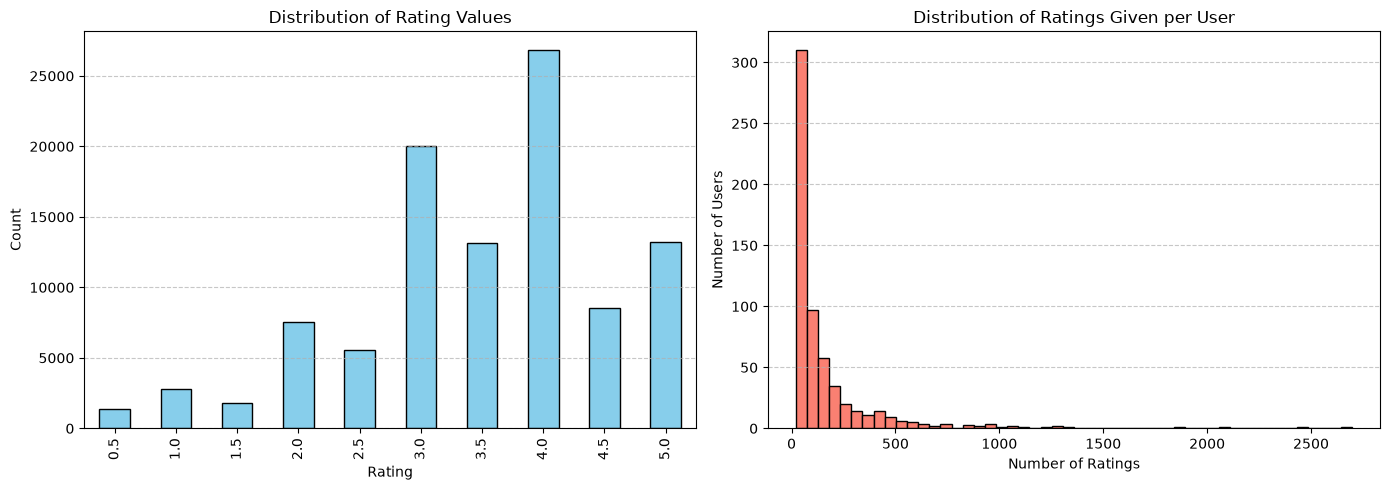

In [3]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1,2, figsize=(14,5))

ratings['rating'].value_counts().sort_index().plot(
    kind='bar', ax=axes[0], color='skyblue', edgecolor='black'
)
axes[0].set_title('Distribution of Rating Values')
axes[0].set_xlabel('Rating')
axes[0].set_ylabel('Count')
axes[0].grid(axis='y', linestyle='--', alpha=0.7)

user_activity = ratings.groupby('userId').size()
axes[1].hist(user_activity, bins=50, color='salmon', edgecolor='black')
axes[1].set_title('Distribution of Ratings Given per User')
axes[1].set_xlabel('Number of Ratings')
axes[1].set_ylabel('Number of Users')
axes[1].grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

In [4]:
print(ratings.dtypes)
print("Duplicate (user, movie) pairs:", ratings.duplicated(['userId', 'movieId']).sum())
print("Movies in movies.csv:", movies['movieId'].nunique(), "| rated:", unique_movies)
print(user_activity.describe())

userId         int64
movieId        int64
rating       float64
timestamp      int64
dtype: object
Duplicate (user, movie) pairs: 0
Movies in movies.csv: 9742 | rated: 9724
count     610.000000
mean      165.304918
std       269.480584
min        20.000000
25%        35.000000
50%        70.500000
75%       168.000000
max      2698.000000
dtype: float64


## Part A observations

### Dataset size and sparsity
The data has 100,836 ratings from 610 users on 9,724 movies. `movies.csv` lists 9,742 movies, but 18 of them have no ratings, so they never appear in the matrix. **The sparsity denominator is users × the 9,724 rated movies**, which is the size of the rating matrix. This gives a sparsity of about 0.983, so roughly 98.3% of user–movie cells are empty. The NaN fraction of the pivot table matches this value. There are no duplicate (user, movie) pairs, so `pivot_table` did not average anything.

### Rating values
Ratings are on a 0.5–5.0 scale in half-star steps. The most frequent rating is 4.0 (~26.8k), followed by 3.0 (~20.0k), then 5.0 and 3.5 (each ~13k). The distribution is skewed toward the high end, and whole-star ratings are more common than half-star ones. This is likely selection bias: people mostly rate movies they chose to watch, and those are usually movies they expected to like. It also means a prediction near 3.5–4 is already a fairly strong baseline.

### User activity
The per-user rating counts are heavily long-tailed. Every user has at least 20 ratings, because the dataset only includes users with that many. The median user has only ~70 ratings, while the most active user has ~2,700. A small group of power users therefore contributes a large share of all ratings, and most users share very few movies with any other user. This matters for the co-rated rule in Section 3.4: many user pairs will have too little overlap to compare reliably.

## Part B — Similarities from scratch (25 points) — B

Implement all four functions below. `axis="index"` compares users; `axis="columns"` compares items. Return aligned vectors containing only shared observed ratings. Never fill missing entries with zero for similarity computation.

Euclidean similarity: compute distance, then convert with `1/(1+d)`. Cosine: dot product divided by the product of norms. Pearson: center both co-rated vectors, then compute cosine. Basic NumPy math is permitted; prebuilt similarity/correlation routines are not.

Skip pairs with fewer than two shared observations. Decide and document zero-norm/zero-variance behavior.

**Important handout correction:** for `[5,4,5,3]` and `[3,2,3,1]`, Euclidean **distance** is 4, but the required Euclidean **similarity** is 0.2. Cosine is about 0.987164; Pearson is 1.0. Show the hand arithmetic as well as your function outputs.

In [5]:
def get_co_rated(matrix, a, b, axis):
    """Return two aligned vectors for shared observed ratings."""
    if axis == 'index':
        vec_a = matrix.loc[a]
        vec_b = matrix.loc[b]
    elif axis == 'columns':
        vec_a = matrix[a]
        vec_b = matrix[b]
    else:
        raise ValueError("Axis must be 'index' or 'columns'.")
    co_rated_mask = vec_a.notna() & vec_b.notna()
    return (vec_a[co_rated_mask].to_numpy(), vec_b[co_rated_mask].to_numpy())

def euclidean_similarity(vec1, vec2):
    """Return Euclidean similarity, or NaN for insufficient overlap."""
    if len(vec1) < MIN_CO_RATED or len(vec2) < MIN_CO_RATED:
        return np.nan
    euclidean_distance = np.linalg.norm(vec1 - vec2)
    similarity = 1 / (1 + euclidean_distance)
    return similarity

def cosine_similarity(vec1, vec2):
    """Return cosine similarity, or NaN for undefined input."""
    if len(vec1) < MIN_CO_RATED or len(vec2) < MIN_CO_RATED:
        return np.nan
    denominator = np.linalg.norm(vec1) * np.linalg.norm(vec2)
    if denominator == 0:
        return np.nan
    cos = np.dot(vec1, vec2) / denominator
    return cos

def pearson_similarity(vec1, vec2):
    """Return Pearson correlation, or NaN for undefined input."""
    if len(vec1) < MIN_CO_RATED or len(vec2) < MIN_CO_RATED:
        return np.nan
    centered_vec1 = vec1 - np.mean(vec1)
    centered_vec2 = vec2 - np.mean(vec2)
    return cosine_similarity(centered_vec1, centered_vec2)


### Worked-example arithmetic

We compare the ratings `[5, 4, 5, 3]` and `[3, 2, 3, 1]`. The second user gives every movie two points less than the first, but both users have the same relative preferences.

**Euclidean similarity:** Each pair of ratings differs by 2. The distance is √(2² + 2² + 2² + 2²) = 4. Converting this to similarity gives 1 / (1 + 4) = **0.2**.

**Cosine similarity:** The dot product is (5 × 3) + (4 × 2) + (5 × 3) + (3 × 1) = 41. The vector lengths are √75 and √23, so the similarity is 41 / (√75 × √23) ≈ **0.987164**. This is close to 1, but cosine does not completely remove the difference in their rating baselines.

**Pearson correlation:** The average ratings are 4.25 and 2.25. After subtracting each user's average, both vectors become `[0.75, -0.25, 0.75, -1.25]`. Their dot product and the product of their lengths are both 2.75, giving a correlation of **1.0**. Removing the averages reveals that their relative preferences match perfectly.


In [6]:
# STUDENT CHECKS - B

a = np.array([5, 4, 5, 3])
b = np.array([3, 2, 3, 1])

print("Worked example:")
print("Euclidean:", euclidean_similarity(a, b))  # Expected: 0.2
print("Cosine:", cosine_similarity(a, b))        # Expected: about 0.987164
print("Pearson:", pearson_similarity(a, b))      # Expected: about 1.0

# BEGIN AI-GENERATED CHECK
movie_a = full_matrix.columns[0]
movie_b = full_matrix.columns[1]

vec1, vec2 = get_co_rated(
    full_matrix, movie_a, movie_b, "columns"
)

print("Movies:", movie_a, movie_b)
print("Shared users:", len(vec1))
print(vec1)
print(vec2)

print("Euclidean:", euclidean_similarity(vec1, vec2))
print("Cosine:", cosine_similarity(vec1, vec2))
print("Pearson:", pearson_similarity(vec1, vec2))
# END AI-GENERATED CHECK



Worked example:
Euclidean: 0.2
Cosine: 0.9871639953033075
Pearson: 1.0
Movies: 1 2
Shared users: 68
[3.5 4.  3.5 3.  2.5 2.5 4.  3.  4.  4.  3.  4.  3.  3.5 2.  4.  4.5 5.
 4.  4.  4.  3.5 3.5 3.5 5.  4.  4.  4.  4.5 2.  5.  4.  3.5 3.5 4.  5.
 5.  5.  4.  3.  5.  3.5 5.  4.  2.5 4.  4.  5.  4.  4.  4.  4.  3.  4.
 4.5 4.  4.  4.  5.  4.  4.  5.  4.  3.  2.5 3.  4.  2.5]
[3.  3.  3.5 4.  2.5 3.  3.  5.  4.  5.  1.5 3.  3.5 3.  2.  4.  4.  3.5
 4.  4.  2.  2.5 3.  4.  5.  4.  3.5 4.  2.  0.5 4.  2.5 3.  4.  1.5 3.
 4.  3.  3.5 3.  5.  4.  4.  3.  4.  2.5 4.  3.  3.  3.  4.  4.  3.  4.
 2.5 3.  3.5 4.5 4.  4.  3.5 4.5 2.5 2.5 4.  5.  3.5 2. ]
Euclidean: 0.10215341528686521
Cosine: 0.9644641106501717
Pearson: 0.3309783545424254


## Part C — User-based collaborative filtering (20 points) — C

`find_k_nearest_users`: compare the target user with other users, exclude itself, skip insufficient-overlap pairs, and return up to k `(user_id, score)` pairs sorted descending.

`predict_rating_user_based`: obtain the top-k overall first, then retain those who rated the target item. Apply Section 3.5's weighted average with signed weights in the numerator and absolute weights in the denominator. Return None if none of those neighbors rated it. Handle a zero denominator sensibly.

Checks: target excluded, k larger than available neighbors, unknown IDs, no eligible raters, and a case where the nearest neighbor lacks the target rating. Do not silently substitute a baseline prediction.

In [7]:
# AI-assisted cleanup: consistent indentation and overlap setting.
def find_k_nearest_users(matrix, target_user, k, similarity_fn):
    neighbors = []
    for user in matrix.index:
        if user == target_user:
            continue
        vec_target, vec_user = get_co_rated(matrix, target_user, user, axis='index')
        if len(vec_target) < MIN_CO_RATED:
            continue
        similarity = similarity_fn(vec_target, vec_user)
        if np.isnan(similarity):
            continue
        neighbors.append((user, similarity))
    neighbors.sort(key=lambda x: x[1], reverse=True)
    return neighbors[:k]

def predict_rating_user_based(matrix, target_user, target_item, k, similarity_fn):
    neighbors = find_k_nearest_users(matrix, target_user, k, similarity_fn)
    numerator = 0.0
    denominator = 0.0
    for user, similarity in neighbors:
        rating = matrix.loc[user, target_item]
        if pd.isna(rating):
            continue
        numerator += similarity * rating
        denominator += abs(similarity)
    if denominator == 0:
        return None
    return numerator / denominator


In [8]:
# STUDENT CHECKS AND DEMO — C

test_matrix = pd.DataFrame(
    {
        1: [5.0, 4.0, 1.0, np.nan],
        2: [4.0, 4.0, 2.0, 5.0],
        3: [5.0, 3.0, np.nan, 4.0],
        4: [1.0, 2.0, 5.0, 4.0],
        5: [np.nan, 5.0, 4.0, 3.0],
    },
    index=[1, 2, 3, 4]
)

print("Test matrix:")
display(test_matrix)

neighbors = find_k_nearest_users(
 test_matrix,
 target_user=1,
 k=2,
 similarity_fn=pearson_similarity
)

print("\nNearest users to User 1:")
print(neighbors)

prediction = predict_rating_user_based(
 test_matrix,
 target_user=1,
 target_item=5,
 k=2,
 similarity_fn=pearson_similarity
)

print("\nPredicted rating for User 1 on Movie 5:")
print(prediction)

Test matrix:


,1,2,3,4,5
1,5.0,4.0,5.0,1.0,NaN
2,4.0,4.0,3.0,2.0,5.0
3,1.0,2.0,NaN,5.0,4.0
4,NaN,5.0,4.0,4.0,3.0



Nearest users to User 1:
[(2, np.float64(0.7816608327818949)), (4, np.float64(0.2773500981126145))]

Predicted rating for User 1 on Movie 5:
4.476209187230302


## Part D — Item-based collaborative filtering (15 points) — D

Adapt Part C to compare item columns over co-rating users. Select top-k item neighbors first, then retain those rated by the target user. Weight that user's ratings of those neighbors.

Reuse common logic where appropriate and explain any duplication. Verify both methods on a small matrix.

In [9]:
# AI-assisted cleanup: consistent indentation and overlap setting.
def find_k_nearest_items(matrix, target_item, k, similarity_fn):
    neighbors = []
    for item in matrix.columns:
        if item == target_item:
            continue
        vec_target, vec_item = get_co_rated(matrix, target_item, item, axis='columns')
        if len(vec_target) < MIN_CO_RATED:
            continue
        similarity = similarity_fn(vec_target, vec_item)
        if np.isnan(similarity):
            continue
        neighbors.append((item, similarity))
    neighbors.sort(key=lambda x: x[1], reverse=True)
    return neighbors[:k]

def predict_rating_item_based(matrix, target_user, target_item, k, similarity_fn):
    neighbors = find_k_nearest_items(matrix, target_item, k, similarity_fn)
    numerator = 0.0
    denominator = 0.0
    for item, similarity in neighbors:
        rating = matrix.loc[target_user, item]
        if pd.isna(rating):
            continue
        numerator += similarity * rating
        denominator += abs(similarity)
    if denominator == 0:
        return None
    return numerator / denominator


In [10]:
# STUDENT CHECKS AND DEMO — D
neighbors = find_k_nearest_items(
    test_matrix,
    target_item=1,
    k=5,
    similarity_fn=pearson_similarity
)

print("Nearest items to Movie 1:")
print(neighbors)

prediction = predict_rating_item_based(
    test_matrix,
    target_user=1,
    target_item=5,
    k=5,
    similarity_fn=pearson_similarity
)

print("\nPredicted rating for User 1 on Movie 5:")
print(prediction)

Nearest items to Movie 1:
[(5, np.float64(1.0)), (3, np.float64(0.9999999999999998)), (2, np.float64(0.9707253433941508)), (4, np.float64(-1.0))]

Predicted rating for User 1 on Movie 5:
-0.658609607987531


### Q12 — Student-written answer 

I reused get_co_rated, the supplied similarity functions, and the similarity-weighted prediction logic from Part C. I changed the neighbor search from users (rows) to items (columns), so item similarities use axis="columns" and predictions use the target user's ratings of similar items.

## Part E — Evaluation (20 points) — A

1. Split **each user's** ratings into approximately 80% training and 20% testing. Do not use a global random split. Document rounding and ensure every user retains training data.
2. Construct `train_matrix` from training ratings only. Neither similarities nor predictions may read held-out values.
3. Attempt every held-out rating with `evaluate`. Calculate RMSE and MAE over successful predictions and report the fraction for which no prediction was possible.
4. Run all **24 configurations**: `{user, item}` × `{euclidean, cosine, pearson}` × `{5,10,20,50}`.
5. Display a table containing method, metric, k, RMSE, MAE and None fraction. Counts of test and successful predictions are useful extras.

Checks: no train/test overlap; train and test reconstruct the original observations; users retain training ratings; repeated splitting with the same seed is reproducible; RMSE is at least MAE on the same successful subset; the grid has all 24 unique combinations.

You may develop on a smaller sample, but the final table must use the full test set. A user-mean baseline and runtime columns are optional. Caching is optional; if used, preserve exact neighbor semantics and invalidate stale entries. Do not rely on an external results CSV in the submitted notebook.

In [11]:
def train_test_split_ratings(ratings_df, test_fraction=0.2):
    test_df = ratings_df.groupby("userId", group_keys=False).sample(frac=test_fraction, random_state=SEED)
    train_df = ratings_df.drop(test_df.index)
    return (train_df, test_df)

def evaluate(matrix, test_df, k, similarity_fn, method):
    if method not in ('user', 'item'):
        raise ValueError(f'Unknown method: {method}')
    if not isinstance(k, (int, np.integer)) or k < 1:
        raise ValueError('k must be a positive integer.')
    
    predictions = []
    actuals = []
    none_count = 0
    total_test = len(test_df)

    if total_test == 0:
        raise ValueError('Cannot evaluate an empty test set.')
    
    for _, row in test_df.iterrows():
        user_id = row['userId']
        movie_id = row['movieId']
        true_rating = row['rating']

        if user_id not in matrix.index or movie_id not in matrix.columns:
            none_count += 1
            continue

        if method == 'user':
            pred = predict_rating_user_based(matrix, user_id, movie_id, k, similarity_fn)
        elif method == 'item':
            pred = predict_rating_item_based(matrix, user_id, movie_id, k, similarity_fn)
        else:
            raise ValueError(f'Unknown method: {method}')
        
        if pred is None:
            none_count += 1
        else:
            predictions.append(pred)
            actuals.append(true_rating)


    if len(predictions) > 0:
        preds_arr = np.array(predictions)
        actuals_arr = np.array(actuals)
        rmse = np.sqrt(np.mean((actuals_arr - preds_arr) ** 2))
        mae = np.mean(np.abs(actuals_arr - preds_arr))
    else:
        rmse = float('nan')
        mae = float('nan')


    none_fraction = none_count / total_test
    
    return (rmse, mae, none_fraction)


In [12]:
train_df, test_df = train_test_split_ratings(ratings, test_fraction=0.2)
train_matrix = train_df.pivot_table(index='userId', columns='movieId', values='rating')


print(f"Original Total Ratings: {len(ratings)}")
print(f"Training Ratings: {len(train_df)} ({len(train_df)/len(ratings)*100:.1f}%)")
print(f"Testing Ratings: {len(test_df)} ({len(test_df)/len(ratings)*100:.1f}%)")
print(f"Train Matrix Shape: {train_matrix.shape}")

original_pairs = set(zip(ratings['userId'], ratings['movieId']))
train_pairs = set(zip(train_df['userId'], train_df['movieId']))
test_pairs = set(zip(test_df['userId'], test_df['movieId']))

assert len(train_pairs.intersection(test_pairs)) == 0, "Error: Train and test sets overlap!"
assert train_pairs.union(test_pairs) == original_pairs, "Error: Split does not reconstruct original ratings!"
assert train_df['userId'].nunique() == ratings['userId'].nunique(), "A user has no training ratings"
tr2, te2 = train_test_split_ratings(ratings, test_fraction=0.2)
assert train_df.equals(tr2) and test_df.equals(te2), "Split is not reproducible"
print("Verification passed: Train/test split invariants hold perfectly!\n")

Original Total Ratings: 100836
Training Ratings: 80672 (80.0%)
Testing Ratings: 20164 (20.0%)
Train Matrix Shape: (610, 8995)
Verification passed: Train/test split invariants hold perfectly!



In [13]:
def run_grid(train_matrix, test_df):

    similarity_functions = {
        'euclidean': euclidean_similarity,
        'cosine': cosine_similarity,
        'pearson': pearson_similarity
    }

    max_k = max(K_VALUES)  # 50
    grid_results = []

    # AI-generated
    val_matrix = train_matrix.to_numpy(dtype=float)
    user_to_idx = {u: idx for idx, u in enumerate(train_matrix.index)}
    movie_to_idx = {m: idx for idx, m in enumerate(train_matrix.columns)}
    # End AI-generated

    # Pre-extract test arrays once for fast lookup
    test_users = test_df['userId'].to_numpy()
    test_movies = test_df['movieId'].to_numpy()
    test_ratings = test_df['rating'].to_numpy()
    total_test = len(test_df)

    # Only 2 nested loops over (method, metric) instead of 3!
    for method in METHODS:

        # AI-generated
        # Work with rows = users for 'user', or rows = items for 'item'
        mat = val_matrix if method == 'user' else val_matrix.T
        obs = ~np.isnan(mat)
        obs_int = obs.astype(int)
        n_entities = mat.shape[0]
        
        # Only compute neighbors for entities that actually appear in test_df
        target_indices = (
            sorted({user_to_idx[u] for u in np.unique(test_users) if u in user_to_idx})
            if method == 'user'
            else sorted({movie_to_idx[m] for m in np.unique(test_movies) if m in movie_to_idx})
        )
        #End AI-generated


        for metric_name, sim_fn in similarity_functions.items():
            print(f"Running method={method}, metric={metric_name} (computing top {max_k} once)...")
            
            # 1. Compute top-50 neighbors ONCE per unique test user (or test movie)
            top50_cache = {}
            for n, target_idx in enumerate(target_indices, 1):
                target_row = mat[target_idx]
                target_obs = obs[target_idx]

                shared_counts = obs_int @ target_obs.astype(int)
                valid_candidates = np.flatnonzero(shared_counts >= MIN_CO_RATED)

            
                neighbors = []
                for cand_idx in valid_candidates:
                    if cand_idx == target_idx:
                        continue
                    mask = target_obs & obs[cand_idx]
                    sim = sim_fn(target_row[mask], mat[cand_idx, mask])
                    if not np.isnan(sim):
                        neighbors.append((cand_idx, sim))
                    
                neighbors.sort(key=lambda x: x[1], reverse=True)
                top50_cache[target_idx] = neighbors[:max_k]
                if n % 500 == 0:
                    print(f"  {n}/{len(target_indices)} neighbour searches done")
            
            # 2. Extract predictions for k = 5, 10, 20, 50 by slicing the top-50 list
            preds_by_k = {k: [] for k in K_VALUES}
            actuals_by_k = {k: [] for k in K_VALUES}
            nones_by_k = {k: 0 for k in K_VALUES}
            
            for u, m, true_r in zip(test_users, test_movies, test_ratings):
                if u not in train_matrix.index or m not in train_matrix.columns:
                    for k in K_VALUES:
                        nones_by_k[k] += 1
                    continue


                u_idx = user_to_idx[u]
                m_idx = movie_to_idx[m]
                neighbors_50 = top50_cache[u_idx if method == 'user' else m_idx] 
                
                # Slice [:k] for each k in [5, 10, 20, 50]
                for k in K_VALUES:
                    numerator = 0.0
                    denominator = 0.0
                    for neighbor_idx, sim in neighbors_50[:k]:
                        r = val_matrix[neighbor_idx, m_idx] if method == 'user' else val_matrix[u_idx, neighbor_idx]
                        if np.isnan(r):
                            continue
                        numerator += sim * r
                        denominator += abs(sim)
                    
                    if denominator == 0.0:
                        nones_by_k[k] += 1
                    else:
                        preds_by_k[k].append(numerator / denominator)
                        actuals_by_k[k].append(true_r)
            
            # 3. Record metrics for all 4 k-values
            for k in K_VALUES:
                preds_arr = np.array(preds_by_k[k])
                actuals_arr = np.array(actuals_by_k[k])
                rmse = np.sqrt(np.mean((actuals_arr - preds_arr) ** 2))
                mae = np.mean(np.abs(actuals_arr - preds_arr))
                none_fraction = nones_by_k[k] / total_test
                
                grid_results.append({
                    'Method': method,
                    'Metric': metric_name,
                    'k': k,
                    'RMSE': rmse,
                    'MAE': mae,
                    'None Fraction': none_fraction,
                    'n_test': total_test,
                    'n_predicted': len(preds_arr)
                })

    results_df = pd.DataFrame(grid_results)


    assert len(results_df) == 24 and not results_df.duplicated(['Method', 'Metric', 'k']).any()
    valid_errors = results_df[['RMSE', 'MAE']].dropna()
    assert (valid_errors['RMSE'] + 1e-12 >= valid_errors['MAE']).all()
    print("\nGrid verification passed: All 24 unique configurations present and RMSE >= MAE!")

    return results_df

In [16]:
# BEGIN AI-ASSISTED: cross-check run_grid against the reference evaluate()
sample = test_df.sample(15, random_state=SEED)          # keep tiny: evaluate() is slow for item-based
grid_small = run_grid(train_matrix, sample)
fns = {'euclidean': euclidean_similarity, 'cosine': cosine_similarity, 'pearson': pearson_similarity}
for _, r in grid_small[grid_small['k'].isin([5, 50])].iterrows():
    ref = evaluate(train_matrix, sample, int(r['k']), fns[r['Metric']], r['Method'])
    assert np.allclose(ref, (r['RMSE'], r['MAE'], r['None Fraction']), equal_nan=True), r[['Method', 'Metric', 'k']].tolist()
print("run_grid matches evaluate on the sample.")
# END AI-ASSISTED

Running method=user, metric=euclidean (computing top 50 once)...
Running method=user, metric=cosine (computing top 50 once)...
Running method=user, metric=pearson (computing top 50 once)...
Running method=item, metric=euclidean (computing top 50 once)...
Running method=item, metric=cosine (computing top 50 once)...
Running method=item, metric=pearson (computing top 50 once)...

Grid verification passed: All 24 unique configurations present and RMSE >= MAE!
run_grid matches evaluate on the sample.


In [17]:

results_df = run_grid(train_matrix, test_df)             # the full-test-set run for the final table
display(results_df.sort_values(['Method', 'Metric', 'k']).reset_index(drop=True)
        .style.format({'RMSE': '{:.4f}', 'MAE': '{:.4f}', 'None Fraction': '{:.3f}'}))

Running method=user, metric=euclidean (computing top 50 once)...
  500/610 neighbour searches done
Running method=user, metric=cosine (computing top 50 once)...
  500/610 neighbour searches done
Running method=user, metric=pearson (computing top 50 once)...
  500/610 neighbour searches done
Running method=item, metric=euclidean (computing top 50 once)...
  500/4386 neighbour searches done
  1000/4386 neighbour searches done
  1500/4386 neighbour searches done
  2000/4386 neighbour searches done
  2500/4386 neighbour searches done
  3000/4386 neighbour searches done
  3500/4386 neighbour searches done
  4000/4386 neighbour searches done
Running method=item, metric=cosine (computing top 50 once)...
  500/4386 neighbour searches done
  1000/4386 neighbour searches done
  1500/4386 neighbour searches done
  2000/4386 neighbour searches done
  2500/4386 neighbour searches done
  3000/4386 neighbour searches done
  3500/4386 neighbour searches done
  4000/4386 neighbour searches done
Running

,Method,Metric,k,RMSE,MAE,None Fraction,n_test,n_predicted
0,item,cosine,5,1.2045,0.9086,0.725,20164,5542
1,item,cosine,10,1.1675,0.8818,0.625,20164,7556
2,item,cosine,20,1.1485,0.8711,0.525,20164,9585
3,item,cosine,50,1.1171,0.8472,0.395,20164,12209
4,item,euclidean,5,1.1469,0.8568,0.721,20164,5621
5,item,euclidean,10,1.1111,0.8289,0.621,20164,7648
6,item,euclidean,20,1.0806,0.8101,0.517,20164,9735
7,item,euclidean,50,1.0446,0.7814,0.383,20164,12438
8,item,pearson,5,1.2959,0.9647,0.688,20164,6293
9,item,pearson,10,1.2605,0.9351,0.585,20164,8361


## Part F — Written analysis (15 points) — A/B/C

Write original responses based on your implementation and outputs. Do not replace them with generic definitions.

**Q16 — A:** Which metric performed best? Quote your actual RMSE/MAE results, consider coverage, and discuss agreement or disagreement with Section 3.2. Do not assume Pearson must win.

**Q17 — B:** Construct your own two-user, 3–4-item example, different from the handout, illustrating disagreement between Euclidean similarity and Pearson. Show calculations. The word “rank” is ambiguous for one pair; a literal reversal between multiple pairs is an optional extension, not an explicit extra requirement.

**Q18 — C:** For 200 million users and 20,000 products, which direction of comparison is cheaper to keep up to date? Explain the scale of comparisons, updates after new ratings, and implications for industry practice.

### Q16 — Answer

From the full results, item-based Euclidean with k = 50 has the lowest error among all 24 configurations, with RMSE of 1.0446 and MAE of 0.7814. It predicted 12,438 out of 20,164 test ratings, about 61.7%, so these errors apply only to that subset. It performed best here, possibly because Euclidean finds movies with similar actual rating values, which fits our raw-rating prediction formula. This differs from Section 3.2’s intuition about Pearson: matching rating patterns did not give the lowest prediction error in our experiment.

### Q17 — Student-written answer

| User | Movie 1 | Movie 2 | Movie 3 | Movie 4 |
|---|---:|---:|---:|---:|
| A | 1 | 4 | 3 | 3 |
| B | 2 | 5 | 4 | 4 |

**Euclidean similarity:**

$$
d=\sqrt{(1-2)^2+(4-5)^2+(3-4)^2+(3-4)^2}=2
$$

$$
\text{Similarity}=\frac{1}{1+2}=\frac13\approx0.333
$$

**Pearson correlation:**

$$
\bar A=\frac{1+4+3+3}{4}=2.75,\qquad
\bar B=\frac{2+5+4+4}{4}=3.75
$$

After subtracting their means, both vectors become:

$$
[-1.75,\ 1.25,\ 0.25,\ 0.25]
$$

$$
\text{Pearson}=
\frac{(-1.75)^2+(1.25)^2+(0.25)^2+(0.25)^2}
{\sqrt{4.75}\times\sqrt{4.75}}
=\frac{4.75}{4.75}=1
$$

Euclidean similarity is about 0.333 because their actual ratings differ. Pearson is 1 because they have the same rating pattern: User B gives every movie one point more than User A.

#**AI assistance disclosure:** I independently selected both users’ ratings. AI assisted with completing and verifying the calculations, formatting the table and mathematical expressions, and refining the written explanation.

### Q18 — Student-written answer

Item-based comparisons are cheaper because there are only 20,000 products compared with 200 million users. Comparing users at this scale requires much more computation and memory. When a new rating is added, the affected similarities need updating. With fewer products to compare, item-based filtering is easier to maintain, which helps explain its use in industry.

## Optional bonus — Up to 10 extra points total

Finish the mandatory work first. The rubric allows either bonus task to be attempted.

**Bonus 1 — B:** Implement a separate mean-centered user-based predictor. Subtract each neighbor's training-rating mean before weighting and add the target user's training-rating mean afterward. Compare its RMSE with plain Pearson-weighted prediction and explain the relationship. Do not replace the mandatory predictor.

**Bonus 2 — A:** Choose a user, predict ratings for unrated movies, and show the top 10. Attach titles/genres from `movies.csv` and sanity-check the genres against that user's rating history. Document which matrix you use.

In [21]:
print(full_matrix.count(axis=1).sort_values(ascending=False).head(10))

userId
414    2698
599    2478
474    2108
448    1864
274    1346
610    1302
68     1260
380    1218
606    1115
288    1055
dtype: int64


In [ ]:
user_id = 414
k = 50
matrix = full_matrix
user_ratings = matrix.loc[user_id]

neighbors = find_k_nearest_users(matrix, user_id, k, pearson_similarity)

print(f"User {user_id}: full_matrix, user-based Pearson, k = {k}")
print("Neighbors found:", len(neighbors))


User 414: full_matrix, user-based Pearson, k = 50
Neighbors found: 50


In [22]:
predictions = []

for movie_id in user_ratings[user_ratings.isna()].index:
    total = 0
    weight = 0
    count = 0

    for neighbor_id, similarity in neighbors:
        rating = matrix.loc[neighbor_id, movie_id]
        if pd.notna(rating):
            total += similarity * rating
            weight += abs(similarity)
            count += 1

    if weight > 0:
        predictions.append([movie_id, total / weight, count])

top_10 = pd.DataFrame(predictions, columns=["movieId", "predicted_rating", "neighbor_count"])
top_10 = top_10.sort_values(["predicted_rating", "movieId"], ascending=[False, True]).head(10)
top_10 = top_10.merge(movies[["movieId", "title", "genres"]], on="movieId", validate="one_to_one")

assert len(top_10) == 10, "Fewer than 10 recommendations were possible."

display(top_10)

,movieId,predicted_rating,neighbor_count,title,genres
0,99,5.0,1,Heidi Fleiss: Hollywood Madam (1995),Documentary
1,148,5.0,1,"Awfully Big Adventure, An (1995)",Drama
2,213,5.0,1,Burnt by the Sun (Utomlyonnye solntsem) (1994),Drama
3,229,5.0,1,Death and the Maiden (1994),Drama|Thriller
4,246,5.0,2,Hoop Dreams (1994),Documentary
5,299,5.0,1,Priest (1994),Drama
6,347,5.0,1,Bitter Moon (1992),Drama|Film-Noir|Romance
7,496,5.0,1,What Happened Was... (1994),Comedy|Drama|Romance|Thriller
8,581,5.0,1,"Celluloid Closet, The (1995)",Documentary
9,668,5.0,1,Song of the Little Road (Pather Panchali) (1955),Drama


In [23]:
liked_movies = user_ratings[user_ratings >= 4].reset_index()
liked_movies.columns = ["movieId", "rating"]
liked_movies = liked_movies.merge(movies[["movieId", "title", "genres"]], on="movieId")

display(liked_movies.sort_values(["rating", "movieId"], ascending=[False, True]).head(20))

,movieId,rating,title,genres
2,11,5.0,"American President, The (1995)",Comedy|Drama|Romance
5,32,5.0,Twelve Monkeys (a.k.a. 12 Monkeys) (1995),Mystery|Sci-Fi|Thriller
6,34,5.0,Babe (1995),Children|Drama
9,50,5.0,"Usual Suspects, The (1995)",Crime|Mystery|Thriller
12,94,5.0,Beautiful Girls (1996),Comedy|Drama|Romance
15,110,5.0,Braveheart (1995),Action|Drama|War
16,111,5.0,Taxi Driver (1976),Crime|Drama|Thriller
22,151,5.0,Rob Roy (1995),Action|Drama|Romance|War
33,223,5.0,Clerks (1994),Comedy
40,260,5.0,Star Wars: Episode IV - A New Hope (1977),Action|Adventure|Sci-Fi


In [24]:
def count_genres(movie_list):
    counts = {}
    for genres in movie_list["genres"]:
        for genre in genres.split("|"):
            counts[genre] = counts.get(genre, 0) + 1
    return pd.Series(counts, dtype=int)

genre_comparison = pd.DataFrame({"liked_count": count_genres(liked_movies), "recommended_count": count_genres(top_10)})
genre_comparison = genre_comparison.fillna(0).astype(int)

genre_comparison["liked_share"] = np.nan
if len(liked_movies) > 0:
    genre_comparison["liked_share"] = genre_comparison["liked_count"] / len(liked_movies)

genre_comparison["recommended_share"] = genre_comparison["recommended_count"] / len(top_10)

display(genre_comparison.sort_values("recommended_count", ascending=False))

,liked_count,recommended_count,liked_share,recommended_share
Drama,694,7,0.565607,0.7
Documentary,34,3,0.027710,0.3
Romance,225,2,0.183374,0.2
Thriller,242,2,0.197229,0.2
Film-Noir,9,1,0.007335,0.1
Comedy,443,1,0.361043,0.1
Action,253,0,0.206194,0.0
(no genres listed),2,0,0.001630,0.0
Animation,86,0,0.070090,0.0
Adventure,211,0,0.171964,0.0


### Student-written bonus discussion

TODO: Include only if a bonus is attempted.